# Reproducing *Geometric Phase Transition Enables Extreme Hippocampal Memory Capacity* (Raju, 2026, arXiv:2605.17199)

This notebook re-runs the paper's methodology end to end on the public Payne, Lynch & Aronov (2021) dataset, using the
author's own code (`hippocampal-stability-main/`) wherever possible, and then stress-tests each claim.

**Layout**

| Part | Paper section | What it tests |
|---|---|---|
| 0 | Methods A.1–A.3 | Data loading, E/I classification, session matrices |
| 1 | Tier 1 (Fig. 1, S1–S3, S7) | "Crystal vs mist": Shesha, Mantel, controls, alternative metrics, Valiant SMA metrics |
| 2 | Tier 2 (Fig. 2, S4) | E/I contributions: Shesha by type, synergy test, Bayesian Δ, principal angles, dimensionality |
| 3 | Tier 3 (Fig. 3, S5) | Capacity model (crystal / mist / noise), topology sweep, parameter sweep, empirical redundancy |
| 4 | — | Claim-by-claim verdict |

Each part has two layers: **Reproduce** (the paper's pipeline, same parameters) and **Stress test** (does the
interpretation survive an obvious alternative explanation?).

**Environment (Anaconda):**
```
conda create -n hippo python=3.11 numpy scipy pandas scikit-learn statsmodels matplotlib tqdm jupyter -c conda-forge
conda activate hippo
pip install shesha-geometry
```
**Data:** download `payne_et_al_2021_data.zip` from Dryad (doi:10.5061/dryad.pg4f4qrp7) and copy `RESULTS_T.mat`
and `RESULTS_Z.mat` into `hippocampal-stability-main/data/raw/`. The first run builds `data/aronov_dataset.pkl`.

In [1]:
import importlib.util, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, cdist, squareform
from scipy.stats import mannwhitneyu, spearmanr, wilcoxon, rankdata
from scipy.ndimage import gaussian_filter, label as ndi_label
import statsmodels.formula.api as smf

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 9})

REPO = Path('hippocampal-stability-main')
RAW = REPO / 'data' / 'raw'
PKL = REPO / 'data' / 'aronov_dataset.pkl'
GRID = 40
NB = GRID * GRID
C_T, C_Z = '#C62D50', '#1C3D8F'     # chickadee, finch (paper colours)
C_E, C_I = '#2E8B57', '#FF8C00'
N_PERM_MANTEL = 200   # paper: 1000
MAX_BINS = 600   # bins per Shesha evaluation in iterated analyses; None = all active bins (exact, ~5x slower)

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, str(path))
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

build = load_module('build_dataset', REPO / 'build_dataset.py')
t3mod = load_module('tier3_capacity', REPO / 'tier 3' / 'tier3_capacity_redundancy.py')
import shesha
print('shesha-geometry', getattr(shesha, '__version__', '?'))

shesha-geometry 0.2.29


---
# Part 0 — Data (Methods A.1–A.3)

Payne et al. (2021) recorded single units in the hippocampal formation of tufted titmice/black-capped chickadees
(food-caching; the code labels them `titmouse`) and zebra finches (non-caching) foraging in an open arena. The
`RESULTS_*.mat` files hold one row per unit with a 40×40 occupancy-normalised rate map (`map`), Skaggs spatial
information (`info`, bits/spike), a within-session first-half/second-half map correlation (`xcorr_map`), waveform
features and anatomy. The author's `build_dataset.py` parses the MATLAB table objects and labels units E/I with Ward
clustering on (spike width, peak/peak ratio). We call those functions directly.

In [ ]:
if PKL.exists():
    df = pd.read_pickle(PKL)
else:
    assert (RAW / 'RESULTS_T.mat').exists(), f'Put RESULTS_T.mat and RESULTS_Z.mat in {RAW.resolve()}'
    rt = build.load_results_table(RAW / 'RESULTS_T.mat')
    rz = build.load_results_table(RAW / 'RESULTS_Z.mat')
    rt['cell_type'] = build.classify_ei(rt, 'Titmouse'); rt['species'] = 'titmouse'
    rz['cell_type'] = build.classify_ei(rz, 'Zebra finch'); rz['species'] = 'zebra_finch'
    if 'subdivision' not in rz.columns:
        rz['subdivision'] = np.nan
    df = pd.concat([rt, rz], ignore_index=True)
    df['spike_width_ms'] = df['spike_width'] * 1000
    pv = []
    for _, r in df.iterrows():
        sh, iv = r.get('info_shuffle'), r.get('info')
        pv.append(np.mean(sh >= iv) if isinstance(sh, np.ndarray) and sh.size and np.isfinite(iv) else np.nan)
    df['info_pvalue'] = pv
    df['spatially_selective'] = df['info_pvalue'] < 0.01
    PKL.parent.mkdir(parents=True, exist_ok=True)
    df.to_pickle(PKL)

df['sp'] = df['species'].map({'titmouse': 'chickadee', 'zebra_finch': 'finch'})
print(df.groupby(['sp', 'cell_type']).size().unstack())
m0 = df['map'].iloc[0]
print('\nmap type/shape:', type(m0), np.shape(m0), '| NaN fraction in first map:', np.isnan(np.asarray(m0, float)).mean().round(3))
print('columns:', [c for c in df.columns if c not in ('waveform', 'info_shuffle', 'xcorr_map_shuffle', 'map', 'delay_info', 'delay_xcorr')])

### Sessions, birds, and how the scripts group them

`tier1.py` groups units by `(bird, session)`, while `tier1_valiant_shesha.py`, `tier2_ei_stability.py` and
`tier3_capacity_redundancy.py` group by `session` alone. Those agree only if session IDs are unique across birds.

In [ ]:
for sp_, g in df.groupby('sp'):
    n_bs = g.groupby(['bird', 'session']).ngroups
    n_s = g['session'].nunique()
    print(f"{sp_:9s}: birds={g['bird'].nunique()}, (bird,session) pairs={n_bs}, unique session IDs={n_s}")
print('\nexample session IDs:', df['session'].drop_duplicates().head(6).tolist())

In [ ]:
def session_mats(sub, keys=('bird', 'session'), min_n=5, fill_nan=True):
    """Stack 40x40 maps of the units in each group into an (n_neurons, 1600) matrix."""
    out = []
    for k, g in sub.groupby(list(keys)):
        maps = [np.asarray(m, float).reshape(-1) for m in g['map'] if m is not None and np.size(m) == NB]
        if len(maps) < min_n:
            continue
        M = np.vstack(maps)
        if fill_nan:
            M = np.nan_to_num(M, nan=0.0)
        out.append(dict(key=k if isinstance(k, tuple) else (k,), bird=g['bird'].iloc[0], M=M, n=len(maps),
                        mean_info=g['info'].mean(), frac_sel=g['spatially_selective'].mean(),
                        subdivision=g['subdivision'].iloc[0] if 'subdivision' in g else np.nan))
    return out

E = df[df.cell_type == 'E']
S = {sp_: session_mats(E[E.sp == sp_]) for sp_ in ['chickadee', 'finch']}
S_raw = {sp_: session_mats(E[E.sp == sp_], fill_nan=False) for sp_ in ['chickadee', 'finch']}
for sp_ in S:
    ns = [s['n'] for s in S[sp_]]
    print(f"{sp_:9s}: {len(ns)} sessions with >=5 E cells; neurons/session median {np.median(ns):.0f} (range {min(ns)}-{max(ns)}); "
          f"birds = {len(set(s['bird'] for s in S[sp_]))}")

---
# Part 1 — Tier 1: is the chickadee code a "crystal" and the finch code a "mist"?

**Shesha (feature-split RDM stability).** For one session, take the $N\times S$ matrix of z-scored E-cell rate maps,
keep "active" bins (≥ max(2, ⌊N/3⌋) neurons firing), split the neurons into two random halves, build a bin×bin cosine
RDM from each half, and Spearman-correlate the two RDMs. Average over random splits. High Shesha = two disjoint subsets
of neurons imply the same similarity structure among locations.

**Mantel test.** Spearman correlation between pairwise physical distance of bins and pairwise neural distance
(RMS difference of z-scored rates), 1000 bin-label permutations. Here `N_PERM_MANTEL` permutations (default 200;
the smallest attainable p is 1/200, enough to classify sessions as significant at 0.05).

The repository contains two Shesha implementations: `tier1.py` (zero-filled maps, `shesha.feature_split` with package
defaults → 30 splits, **no seed**) and `tier1_valiant_shesha.py` (NaN-masked distances, 100 splits, seed 320). The paper's
Methods describe the second but say Tier 1 uses the first with "defaults … 100 splits, seed 320"; the installed package's
actual defaults are 30 splits and `seed=None`. We compute both.

In [ ]:
t1 = load_module('tier1', REPO / 'tier 1' / 'tier1.py')
t1v = load_module('tier1_valiant', REPO / 'tier 1' / 'tier1_valiant_shesha.py')
from shesha import feature_split

def shesha_t1(M, n_splits=30, seed=320, max_samples=1600):
    """tier1.compute_shesha, with the seed made explicit (the original passes none)."""
    n = M.shape[0]
    mu, sd = M.mean(1, keepdims=True), M.std(1, keepdims=True); sd[sd == 0] = 1
    Mz = (M - mu) / sd
    act = np.where(np.sum(M > 0, 0) >= max(2, n // 3))[0]
    if len(act) < 30 or n < 4:
        return np.nan
    return feature_split(Mz[:, act].T, n_splits=n_splits, seed=seed, max_samples=max_samples)

def shesha_masked(M_raw, n_splits=100, seed=320, max_bins=MAX_BINS):
    """tier1_valiant_shesha.compute_shesha (NaN-aware z-scoring, masked cosine RDMs, Spearman), with optional
    random subsampling of active bins for speed. Identical to the author's function when max_bins=None and the
    active bins contain no NaNs (checked below)."""
    n = M_raw.shape[0]
    mu, sd = np.nanmean(M_raw, 1, keepdims=True), np.nanstd(M_raw, 1, keepdims=True); sd[sd == 0] = 1
    Mz = (M_raw - mu) / sd
    act = np.where(np.sum(np.isfinite(M_raw) & (M_raw > 0), 0) >= max(2, n // 3))[0]
    if len(act) < 30 or n < 4:
        return np.nan
    X = Mz[:, act].T
    if not np.all(np.isfinite(X)):
        return t1v.compute_shesha(M_raw, n_splits=n_splits)[0]
    rng = np.random.RandomState(seed)
    if max_bins is not None and len(act) > max_bins:
        X = X[np.sort(rng.choice(len(act), max_bins, replace=False))]
    out = []
    for _ in range(n_splits):
        p = rng.permutation(n); h = n // 2
        r1, r2 = pdist(X[:, p[:h]], 'cosine'), pdist(X[:, p[h:2*h]], 'cosine')
        ok = np.isfinite(r1) & np.isfinite(r2)
        if ok.sum() >= 10:
            r = spearmanr(r1[ok], r2[ok])[0]
            if np.isfinite(r): out.append(r)
    return np.mean(out) if out else np.nan

def mantel_fast(M_raw, n_perms=1000, seed=320):
    """Same statistic as tier1_valiant_shesha.compute_mantel_test; permutations done on the rank matrix
    (Spearman r is invariant to where a value sits, so permuting bins = permuting rows/cols of rank(D))."""
    n = M_raw.shape[0]
    mu, sd = np.nanmean(M_raw, 1, keepdims=True), np.nanstd(M_raw, 1, keepdims=True); sd[sd == 0] = 1
    Mz = (M_raw - mu) / sd
    act = np.where(np.sum(np.isfinite(M_raw) & (M_raw > 0), 0) >= max(2, n // 3))[0]
    if len(act) < 50:
        return np.nan, np.nan
    X = Mz[:, act].T
    if not np.all(np.isfinite(X)):                       # fall back to the author's masked routine
        r, p, _ = t1v.compute_mantel_test(M_raw, n_perms=n_perms); return r, p
    rc = np.column_stack([act // GRID, act % GRID])
    phys = pdist(rc); neural = pdist(X) / np.sqrt(n)
    iu = np.triu_indices(len(act), 1)
    rp = rankdata(phys); rp = (rp - rp.mean()) / rp.std()
    Rn = np.zeros((len(act), len(act))); Rn[iu] = rankdata(neural); Rn = Rn + Rn.T
    def r_of(perm):
        v = Rn[np.ix_(perm, perm)][iu]; v = (v - v.mean()) / v.std(); return np.mean(rp * v)
    r_obs = r_of(np.arange(len(act)))
    rng = np.random.RandomState(seed)
    null = np.array([r_of(rng.permutation(len(act))) for _ in range(n_perms)])
    return r_obs, np.mean(null >= r_obs)

def cohen_d(x, y):
    x, y = np.asarray(x), np.asarray(y)
    sp = np.sqrt(((len(x)-1)*x.var(ddof=1) + (len(y)-1)*y.var(ddof=1)) / (len(x)+len(y)-2))
    return (x.mean() - y.mean()) / sp

def compare(x, y, alt='greater', label=''):
    x, y = np.asarray(x)[np.isfinite(x)], np.asarray(y)[np.isfinite(y)]
    p = mannwhitneyu(x, y, alternative=alt).pvalue
    print(f"{label:38s} chickadee {x.mean():.3f} (med {np.median(x):.3f}, n={len(x)}) | finch {y.mean():.3f} "
          f"(med {np.median(y):.3f}, n={len(y)}) | MW {alt} p={p:.4f} | d={cohen_d(x, y):.2f}")
    return p

# sanity checks on one session: fast re-implementations = author's functions
s0 = S_raw['chickadee'][0]
print('Mantel r : author', round(t1v.compute_mantel_test(s0['M'], n_perms=5)[0], 4), '| fast', round(mantel_fast(s0['M'], n_perms=5)[0], 4))
print('Shesha (masked, 10 splits): author', round(t1v.compute_shesha(s0['M'], n_splits=10)[0], 4),
      '| re-implementation', round(shesha_masked(s0['M'], n_splits=10, max_bins=None), 4))

## 1.1 Reproduce: Shesha and Mantel by species

In [ ]:
t0 = time.time()
rows = []
for sp_ in ['chickadee', 'finch']:
    for s, sr in zip(S[sp_], S_raw[sp_]):
        r_m, p_m = mantel_fast(sr['M'], n_perms=N_PERM_MANTEL)
        rows.append(dict(sp=sp_, bird=s['bird'], key=s['key'], n=s['n'], mean_info=s['mean_info'], frac_sel=s['frac_sel'],
                         subdivision=s['subdivision'],
                         shesha_t1=shesha_t1(s['M']),                       # tier1.py pipeline, all bins
                         shesha_masked=shesha_masked(sr['M']),               # tier1_valiant_shesha pipeline
                         mantel_r=r_m, mantel_p=p_m,
                         pv_corr=t1.compute_test_retest_pv(s['M']),
                         cca=t1.compute_cca_stability(s['M'])))
T1 = pd.DataFrame(rows)
print(f'({time.time()-t0:.0f} s)')
ck, fz = T1[T1.sp == 'chickadee'], T1[T1.sp == 'finch']
compare(ck.shesha_t1, fz.shesha_t1, label='Shesha (tier1.py, 30 splits)')
compare(ck.shesha_masked, fz.shesha_masked, label='Shesha (masked, valiant script)')
compare(ck.mantel_r, fz.mantel_r, alt='two-sided', label='Mantel r')
print(f"Mantel significant (p<0.05): chickadee {np.sum(ck.mantel_p < 0.05)}/{ck.mantel_p.notna().sum()}, "
      f"finch {np.sum(fz.mantel_p < 0.05)}/{fz.mantel_p.notna().sum()}")
compare(ck.pv_corr, fz.pv_corr, label='PV split-half correlation')
compare(ck.cca, fz.cca, label='CCA stability')
xc = df[df.cell_type == 'E']
compare(xc[xc.sp == 'chickadee'].xcorr_map, xc[xc.sp == 'finch'].xcorr_map, label='within-session map xcorr (per E cell)')

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, col, ttl in zip(ax, ['shesha_t1', 'mantel_r', 'pv_corr', 'cca'], ['Shesha', 'Mantel r', 'PV correlation', 'CCA stability']):
    for i, (sp_, c) in enumerate([('chickadee', C_T), ('finch', C_Z)]):
        v = T1.loc[T1.sp == sp_, col].dropna()
        a.scatter(i + np.random.uniform(-.12, .12, len(v)), v, s=14, c=c, alpha=.7)
        a.plot([i - .2, i + .2], [v.median()] * 2, c='k', lw=2)
    a.set_xticks([0, 1]); a.set_xticklabels(['chickadee', 'finch']); a.set_title(ttl)
plt.tight_layout(); plt.show()

## 1.2 Reproduce: negative controls (Fig. S3A–B)

*Circular shift*: each neuron's flattened 1600-bin map is rolled by a random offset. *Map shuffle*: each neuron's bins
are permuted. *Neuron-matched*: chickadee sessions subsampled to the finch median N.
Runtime: every Shesha evaluation correlates two RDMs with up to ~10⁶ entries, so the iterated controls subsample
`MAX_BINS` active bins per evaluation and use 10 iterations (paper: 20) / 20 repeats (paper: 50). These are averages,
so this adds a little noise but no bias. Set `MAX_BINS = None` at the top for the exact settings (slow).

In [ ]:
np.random.seed(320)
ctrl = []
for sp_ in ['chickadee', 'finch']:
    for s in S[sp_]:
        circ = np.nanmean([shesha_t1(t1.create_circular_shifted_control(s['M']), max_samples=MAX_BINS) for _ in range(10)])
        shuf = np.nanmean([shesha_t1(t1.create_map_shuffle_control(s['M']), max_samples=MAX_BINS) for _ in range(10)])
        ctrl.append(dict(sp=sp_, key=s['key'], circ=circ, shuf=shuf))
T1 = T1.merge(pd.DataFrame(ctrl), on=['sp', 'key'])
print(T1.groupby('sp')[['shesha_t1', 'circ', 'shuf']].mean().round(3))

target = int(np.median([s['n'] for s in S['finch']]))
rng = np.random.RandomState(320)
ds = []
for s in S['chickadee']:
    if s['n'] >= target:
        ds.append(np.nanmean([shesha_t1(s['M'][rng.choice(s['n'], target, replace=False)], max_samples=MAX_BINS) for _ in range(20)]))
print(f"\nNeuron-matched (N={target}): {len(ds)} eligible chickadee sessions")
compare(ds, fz.shesha_t1, label='Shesha, chickadee downsampled vs finch')

## 1.3 Reproduce: Valiant "stable memory allocator" metrics (Fig. S2)

In [ ]:
val = []
for sp_ in ['chickadee', 'finch']:
    for sr in S_raw[sp_]:
        vm = t1v.compute_valiant_metrics_revised(sr['M'])
        val.append(dict(sp=sp_, key=sr['key'], field_size_cv=vm['field_size_cv'], alloc_r=vm['split_half_r'],
                        frac_with_fields=vm['frac_with_fields']))
V = pd.DataFrame(val)
compare(V[V.sp == 'chickadee'].field_size_cv, V[V.sp == 'finch'].field_size_cv, alt='two-sided', label='place-field size CV')
compare(V[V.sp == 'chickadee'].alloc_r, V[V.sp == 'finch'].alloc_r, alt='less', label='split-half allocation reliability')

## 1.4 Stress tests

Suppose the Shesha/Mantel differences reproduce (check 1.1). The question is what they mean. Payne et al. (2021) already
reported that chickadee hippocampus has far more, and sharper, place cells than finch hippocampus. Any measure of
"do two random subsets of neurons agree about which locations are similar" will rise with the number and quality of
place cells, without any special population-level organisation. Three checks:

**(a) How much of Shesha survives destroying the population structure but keeping each neuron's own tuning?**
The circular-shift control does exactly that: every neuron keeps its field shape, firing statistics and smoothness, but
fields land at independent random positions — a population of *independent* place cells. If chickadee "crystal"
geometry were a population-level property, the drop (original − shifted) should be larger in chickadees.

In [ ]:
T1['excess'] = T1.shesha_t1 - T1.circ
compare(T1[T1.sp == 'chickadee'].excess, T1[T1.sp == 'finch'].excess, alt='two-sided', label='Shesha − circular-shift Shesha')
compare(T1[T1.sp == 'chickadee'].circ, T1[T1.sp == 'finch'].shesha_t1, alt='two-sided', label='chickadee SHIFTED vs finch ORIGINAL')

**(b) Does species still matter once single-cell spatial information and neuron count are accounted for?**

In [ ]:
T1['log_n'] = np.log(T1.n)
for y in ['shesha_t1', 'mantel_r']:
    fit = smf.ols(f'{y} ~ C(sp) + mean_info + log_n', data=T1).fit()
    print(f"\n{y}:  R² = {fit.rsquared:.2f}")
    print(fit.summary2().tables[1][['Coef.', 'Std.Err.', 'P>|t|']].round(4).to_string())
    print(f"  species-only model: coef = {smf.ols(f'{y} ~ C(sp)', data=T1).fit().params.iloc[1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.2))
for sp_, c in [('chickadee', C_T), ('finch', C_Z)]:
    g = T1[T1.sp == sp_]
    ax[0].scatter(g.mean_info, g.shesha_t1, c=c, s=16, label=sp_); ax[1].scatter(g.n, g.shesha_t1, c=c, s=16)
ax[0].set_xlabel('mean spatial info of E cells in session (bits/spike)'); ax[0].set_ylabel('Shesha'); ax[0].legend(frameon=False)
ax[1].set_xlabel('E cells in session'); plt.tight_layout(); plt.show()

**(c) Sessions are not independent.** Several sessions come from the same bird; the session-level tests treat them as
independent replicates. Aggregating to one value per bird:

In [ ]:
B = T1.groupby(['sp', 'bird'])[['shesha_t1', 'mantel_r']].mean().reset_index()
print(B.groupby('sp').size().rename('birds'))
compare(B[B.sp == 'chickadee'].shesha_t1, B[B.sp == 'finch'].shesha_t1, label='Shesha, bird-level means')
compare(B[B.sp == 'chickadee'].mantel_r, B[B.sp == 'finch'].mantel_r, alt='two-sided', label='Mantel r, bird-level means')

---
# Part 2 — Tier 2: do inhibitory cells "stiffen" the geometry?

Claims (chickadee only): E cells carry ~20× more spatial information than I cells; I cells are as temporally stable;
Shesha(E) > Shesha(I) with a Bayesian Δ = 0.076, 95% CrI [0.024, 0.143]; principal angles between top-3 E and I
subspaces are 14° / 64° / 82° ("one shared, two orthogonal"); adding I cells raises intrinsic dimensionality from
D = 7.5 to 9.8, and the anti-correlated control does not; full-population Shesha > E-only Shesha (synergy).

In [ ]:
t2 = load_module('tier2', REPO / 'tier 2' / 'tier2_ei_stability.py')
t2e = load_module('tier2_enh', REPO / 'tier 2' / 'tier2_enhanced.py')
import contextlib, io

def shesha_t2(M, n_splits=100, min_neurons=4, max_samples=MAX_BINS):
    """tier2_ei_stability.compute_shesha / tier2_enhanced.compute_shesha (identical logic, including NaN propagation),
    with optional bin subsampling (the originals use all active bins)."""
    if M is None or M.shape[0] < min_neurons:
        return np.nan
    n = M.shape[0]
    mu, sd = M.mean(1, keepdims=True), M.std(1, keepdims=True); sd[sd == 0] = 1
    Mz = (M - mu) / sd
    act = np.where(np.sum(M > 0, 0) >= max(2, n // 3))[0]
    if len(act) < 30:
        return np.nan
    try:   # the originals wrap this in try/except and return NaN on failure (e.g. NaN rates)
        return feature_split(Mz[:, act].T, n_splits=n_splits, metric='cosine', seed=320, max_samples=max_samples)
    except ValueError:
        return np.nan
with contextlib.redirect_stdout(io.StringIO()):
    S2 = t2.get_session_maps_by_type(df, 'titmouse')          # primary pipeline (groups by session)
    S2e = t2e.load_chickadee_data_with_cell_types(str(PKL))   # supplementary pipeline (groups by bird, session)
print(f"tier2_ei_stability sessions (>=5 cells): {len(S2)};  with >=3 E and >=3 I: "
      f"{sum(1 for v in S2.values() if v['M_e'] is not None and v['M_i'] is not None)}")
print(f"tier2_enhanced sessions (>=3 E and >=3 I): {len(S2e)}")

ck_cells = df[df.sp == 'chickadee']
cE, cI = ck_cells[ck_cells.cell_type == 'E'], ck_cells[ck_cells.cell_type == 'I']
print(f"\nSpatial info, bits/spike: E mean {cE['info'].mean():.3f}, I mean {cI['info'].mean():.3f}, "
      f"MW p = {mannwhitneyu(cE['info'], cI['info']).pvalue:.1e}")
print(f"Within-session xcorr: E {cE.xcorr_map.mean():.3f}, I {cI.xcorr_map.mean():.3f}, "
      f"MW p = {mannwhitneyu(cE.xcorr_map.dropna(), cI.xcorr_map.dropna()).pvalue:.3f}")
print(f"Fraction spatially selective: E {cE.spatially_selective.mean():.3f}, I {cI.spatially_selective.mean():.3f}")
print(f"Mean firing rate (Hz): E {cE.rate.mean():.2f}, I {cI.rate.mean():.2f}")

Note the units. Skaggs information is **bits per spike**; I cells fire far faster, so a broadly tuned I cell can carry
comparable bits per *second* while scoring near zero per spike. "20× more information" is partly a rate effect.

## 2.1 Reproduce: Shesha by cell type, synergy test, Bayesian Δ

In [ ]:
rows = []
for k, v in S2.items():
    if v['M_e'] is None or v['M_i'] is None:
        continue
    rows.append(dict(session=k, bird=v['bird'], n_e=v['n_e'], n_i=v['n_i'],
                     sh_all=shesha_t2(v['M_all']), sh_e=shesha_t2(v['M_e']), sh_i=shesha_t2(v['M_i']),
                     mantel_e=t2.compute_mantel(v['M_e']), mantel_i=t2.compute_mantel(v['M_i'])))
T2 = pd.DataFrame(rows)
print(T2[['sh_all', 'sh_e', 'sh_i', 'mantel_e', 'mantel_i']].describe().loc[['count', 'mean']].round(3))
pr = T2.dropna(subset=['sh_all', 'sh_e'])
w = wilcoxon(pr.sh_all - pr.sh_e, alternative='greater')
print(f"\nSynergy (full > E-only): {np.sum(pr.sh_all > pr.sh_e)}/{len(pr)} sessions, Wilcoxon one-sided p = {w.pvalue:.4f}")
ei = T2.dropna(subset=['sh_e', 'sh_i'])
print(f"Shesha E vs I (both defined, n={len(ei)}): r(E,I) = {spearmanr(ei.sh_e, ei.sh_i)[0]:.3f} (p={spearmanr(ei.sh_e, ei.sh_i)[1]:.3f})")
m = T2.dropna(subset=['mantel_e', 'mantel_i'])
print(f"Mantel E {m.mantel_e.mean():.3f} vs I {m.mantel_i.mean():.3f}, MW two-sided p = {mannwhitneyu(m.mantel_e, m.mantel_i).pvalue:.3f}")

**Check the matrices `tier2_enhanced.py` builds.** Its loader stacks `row['map']` without flattening; the maps are
40×40 arrays, so the result is not (neurons × 1600 bins).

In [ ]:
s_ = S2e[0]
print(f"tier2_enhanced session 0: n_e={s_['n_e']}, M_e.shape={s_['M_e'].shape}, NaN fraction={np.isnan(s_['M_e']).mean():.2f}")
print(f"same session, true number of E units: {s_['n_e'] // GRID if s_['M_e'].shape[1] == GRID else s_['n_e']}")

def fix(M):
    """(40*n, 40) stack of 40x40 maps -> (n, 1600), NaN -> 0 (as in tier2_ei_stability)."""
    return np.nan_to_num(M.reshape(-1, NB)) if M.shape[1] == GRID else np.nan_to_num(M)

with contextlib.redirect_stdout(io.StringIO()):     # as written (author's function on author's matrices)
    she_w = np.array([t2e.compute_shesha(s['M_e']) for s in S2e]); shi_w = np.array([t2e.compute_shesha(s['M_i']) for s in S2e])
she = np.array([shesha_t2(fix(s['M_e'])) for s in S2e]); shi = np.array([shesha_t2(fix(s['M_i'])) for s in S2e])

for lab, a_, b_ in [('as written', she_w, shi_w), ('corrected matrices', she, shi)]:
    e_ok, i_ok = a_[np.isfinite(a_)], b_[np.isfinite(b_)]
    print(f"\n[{lab}] Shesha E n={len(e_ok)} mean {np.mean(e_ok) if len(e_ok) else np.nan:.3f}; "
          f"I n={len(i_ok)} mean {np.mean(i_ok) if len(i_ok) else np.nan:.3f}")
    if len(e_ok) >= 2 and len(i_ok) >= 2:
        bm, bci = t2e.bayesian_credible_interval(list(e_ok), list(i_ok), n_mcmc=1000)
        print(f"   author's MCMC: Δ = {bm:.3f}, 95% CrI [{bci[0]:.3f}, {bci[1]:.3f}];  Mann-Whitney two-sided p = {mannwhitneyu(e_ok, i_ok).pvalue:.3f}")
    both = np.isfinite(a_) & np.isfinite(b_)
    if both.sum() > 2:
        d_ = a_[both] - b_[both]; rng = np.random.RandomState(320)
        boot = np.array([rng.choice(d_, len(d_)).mean() for _ in range(10000)])
        print(f"   paired (same sessions, n={both.sum()}): mean Δ = {d_.mean():.3f}, bootstrap 95% CI "
              f"[{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}], Wilcoxon p = {wilcoxon(d_).pvalue:.3f}")

**What the author's MCMC does.** `bayesian_credible_interval` fixes the I-population mean and both standard deviations at
their sample values and only lets the E mean move, with a 0.01 random-walk step for 1000 iterations started at the
maximum. The resulting "posterior" is approximately $\mathcal N(\bar x_E-\bar x_I,\ s_E/\sqrt{n_E})$: it ignores
uncertainty in the I mean, ignores that E and I come from the same sessions, and the short, highly autocorrelated chain
understates the spread. Compare its interval with the rank test and the paired bootstrap printed above.

## 2.2 Reproduce + stress test: principal angles between E and I subspaces

In [ ]:
def rot180(M):
    return np.stack([np.rot90(m.reshape(GRID, GRID), 2).ravel() for m in M])

ang = []
rng = np.random.RandomState(320)
for k, v in S2.items():
    if v['M_e'] is None or v['M_i'] is None:
        continue
    a = t2.compute_principal_angles(v['M_e'], v['M_i'], min_neurons=3)
    a_rot = t2.compute_principal_angles(v['M_e'], rot180(v['M_i']), min_neurons=3)     # I maps rotated 180°
    # E-vs-E: two disjoint random halves of the E population
    if v['n_e'] >= 6:
        p_ = rng.permutation(v['n_e']); h = v['n_e'] // 2
        a_ee = t2.compute_principal_angles(v['M_e'][p_[:h]], v['M_e'][p_[h:2*h]], min_neurons=3)
    else:
        a_ee = [np.nan] * 3
    # random 3-D subspaces in the same ambient space
    nb = v['M_e'].shape[1]
    Q1, _ = np.linalg.qr(rng.randn(nb, 3)); Q2, _ = np.linalg.qr(rng.randn(nb, 3))
    a_rand = np.degrees(np.arccos(np.clip(np.linalg.svd(Q1.T @ Q2)[1], -1, 1)))
    ang.append(dict(session=k, n_e=v['n_e'], n_i=v['n_i'], **{f'EI_{j+1}': a[j] for j in range(3)},
                    **{f'EIrot_{j+1}': a_rot[j] for j in range(3)}, **{f'EE_{j+1}': a_ee[j] for j in range(3)},
                    **{f'rand_{j+1}': a_rand[j] for j in range(3)}))
A = pd.DataFrame(ang).dropna(subset=['EI_1'])
print(f"n sessions = {len(A)};  sessions with n_E==3 or n_I==3: {np.sum((A.n_e == 3) | (A.n_i == 3))}")
summ = pd.DataFrame({c: [A[f'{c}_{j}'].mean() for j in (1, 2, 3)] for c in ['EI', 'EIrot', 'EE', 'rand']},
                    index=['angle 1', 'angle 2', 'angle 3']).round(1)
summ.columns = ['E vs I', 'E vs I rotated 180°', 'E vs E (halves)', 'random 3-D subspaces']
print(summ)

Things to read off this table:

* The "~83° expected for random subspaces" quoted in the paper is not what random 3-D subspaces of a ~1600-dimensional
  bin space give (≈90°).
* The code centres each matrix across neurons before the SVD, so a population of $n$ cells spans at most $n-1$
  dimensions. In sessions with 3 E or 3 I cells, the third singular vector is numerical noise and its angle is
  essentially random — that is where the large "angle 3" comes from.
* Whether the first angle reflects a specifically E–I relationship can be judged from the controls: if E vs E halves or
  E vs spatially rotated I also give a small first angle, the "shared axis" is a generic property of spatial rate maps
  (e.g. a common rate modulation by place), not E–I coupling.

## 2.3 Reproduce + stress test: dimensionality expansion and the "knock-out"

In [ ]:
dims = []
for s in S2e:
    Me, Mi = fix(s['M_e']), fix(s['M_i'])
    with contextlib.redirect_stdout(io.StringIO()):
        D_e_w, D_all_w = t2e.estimate_dimensionality(s['M_e']), t2e.estimate_dimensionality(s['M_all'])
        D_anti_w = t2e.estimate_dimensionality(np.vstack([s['M_e'], t2e.create_anticorrelated_i(s['M_e'], None)]))
    dims.append(dict(n_e=Me.shape[0], n_i=Mi.shape[0], D_e_written=D_e_w, D_all_written=D_all_w, D_anti_written=D_anti_w,
                     D_e=t2e.estimate_dimensionality(Me), D_all=t2e.estimate_dimensionality(np.vstack([Me, Mi])),
                     D_e_plus_rotI=t2e.estimate_dimensionality(np.vstack([Me, rot180(Mi)])),
                     D_anti=t2e.estimate_dimensionality(np.vstack([Me, t2e.create_anticorrelated_i(Me, None)])),
                     sh_e=shesha_t2(Me), sh_all=shesha_t2(np.vstack([Me, Mi])), sh_e_rotI=shesha_t2(np.vstack([Me, rot180(Mi)]))))
Dm = pd.DataFrame(dims)
print('As written (40-row blocks):', Dm[['D_e_written', 'D_all_written', 'D_anti_written']].mean().round(2).to_dict())
print('Corrected (neurons x bins):', Dm[['n_e', 'n_i', 'D_e', 'D_all', 'D_e_plus_rotI', 'D_anti']].mean().round(2).to_dict())
print(f"\nShesha: E-only {Dm.sh_e.mean():.3f} | E + real I {Dm.sh_all.mean():.3f} | E + rotated I {Dm.sh_e_rotI.mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.2))
allD = pd.concat([pd.DataFrame({'n': Dm.n_e, 'D': Dm.D_e}), pd.DataFrame({'n': Dm.n_e + Dm.n_i, 'D': Dm.D_all})])
ax[0].scatter(Dm.n_e, Dm.D_e, c=C_E, s=16, label='E only'); ax[0].scatter(Dm.n_e + Dm.n_i, Dm.D_all, c=C_I, s=16, label='E + I')
ax[0].plot([0, allD.n.max()], [0, allD.n.max()], 'k:', lw=0.8, label='D = n')
ax[0].set_xlabel('number of neurons'); ax[0].set_ylabel('PCs for 95% variance'); ax[0].legend(frameon=False)
ax[1].bar(['E only', 'E + I', 'E + rotated I', 'E + anti-E'], Dm[['D_e', 'D_all', 'D_e_plus_rotI', 'D_anti']].mean(),
          color=[C_E, C_I, 'grey', 'lightgrey']); ax[1].set_ylabel('mean D')
plt.tight_layout(); plt.show()

"PCs needed for 95% variance" cannot exceed the number of neurons and, for small noisy populations, tracks it closely.
Adding $n_I$ neurons raises $D$ whether or not those neurons have any meaningful relation to the E map; the relevant
comparison is E + real I against E + the same I cells spatially rotated. The "anti-correlated control" is
$-M_E$ shifted to be non-negative; after z-scoring it is exactly $-Z_E$, which spans the same space as $Z_E$, so it
cannot add dimensions by construction — it is not a test of anything. The same neuron-count logic applies to the
synergy/"knock-out" test: Shesha's split halves get more neurons when I cells are added.

---
# Part 3 — Tier 3: the capacity model

**What the paper does (Methods A.13–A.14).** Synthetic 1-D circular-track codes: $N=500$ neurons with Gaussian tuning
($\sigma=\rho/2$, $\rho=0.15$), additive "functional" noise ($\sigma=0.2$, rectified), and a *topology strength*
$\tau$ = fraction of neurons whose tuning curve is kept in place; the other $(1-\tau)N$ neurons have their tuning curve
randomly permuted across locations. Rows are L2-normalised. *Crystal* = $\tau{=}1$ ("chickadee"), *mist* = $\tau{=}0.5$
("finch"), *noise* = $\tau{=}0$. Decoding: add read-out noise ($\sigma=0.3$ per element) to each stored pattern and
find the nearest stored template, **with the self-match excluded** ($D_{ii}=\infty$). Error = circular distance between
true and decoded location, divided by 0.25 (chance). Capacity = load at which error crosses the midpoint between the
crystal and noise errors at $M=100$.

**Headline claims:** crystal error 0.285 vs mist 0.529 vs noise 0.996 at $M=100$; threshold 0.640; crystal stays below
threshold to $M=1000$ while mist fails at $M=10$ → ">100-fold capacity advantage"; $\tau_{crit}\approx0.35$ "phase
transition"; advantage governed by sparsity and invariant to $N$ and $T$ across 10,000 configurations.

## 3.1 Reproduce the capacity curves (author's functions, same seed)

In [2]:
LOADS = t3mod.MEMORY_LOADS            # [10, 20, 50, 100, 200, 500, 1000]
rng = np.random.RandomState(320)
cap = {}
for name, tau in [('crystal', 1.0), ('mist', 0.5), ('noise', 0.0)]:
    err, mant = t3mod.test_capacity(tau, 500, 0.15, 0.2, 20, LOADS, rng)
    cap[name] = dict(err=err, mantel=mant)
i100 = LOADS.index(100)
thr = (cap['crystal']['err'][i100] + cap['noise']['err'][i100]) / 2
crit = {k: t3mod.find_critical_capacity(v['err'], LOADS, thr) for k, v in cap.items()}
cap_tab = pd.DataFrame({k: v['err'] for k, v in cap.items()}, index=pd.Index(LOADS, name='M')).round(3)
print(cap_tab.T)
print(f"\nthreshold = {thr:.3f};  'critical capacity' = {crit}")
print(f"Mantel r at each load (crystal / mist): {np.round(cap['crystal']['mantel'],2)} / {np.round(cap['mist']['mantel'],2)}")

M         10     20     50     100    200    500    1000
crystal  0.620  0.374  0.303  0.285  0.262  0.256  0.251
mist     0.772  0.706  0.578  0.529  0.509  0.483  0.476
noise    1.054  1.069  1.055  0.996  1.014  1.007  1.002

threshold = 0.640;  'critical capacity' = {'crystal': 1000, 'mist': 10, 'noise': 10}
Mantel r at each load (crystal / mist): [0.6  0.66 0.69 0.7  0.7  0.71 0.71] / [0.57 0.62 0.66 0.66 0.66 0.67 0.67]


The paper's numbers reproduce exactly (0.285 / 0.529 / 0.996; threshold 0.640). Now look at what produced the ">100-fold"
figure:

* `find_critical_capacity` returns the **last tested load** (1000) if the curve never crosses the threshold, and the
  **first tested load** (10) if it is already above threshold at the start. "1000 vs 10" are therefore the two ends of
  the grid, not measured capacities. Crystal at $M=10$ is 0.62 — only 0.02 under the threshold.
* **Every curve decreases with $M$.** Storing more locations makes decoding *better*, the opposite of interference.
  The reason is the decoder.

## 3.2 Stress test: what the self-excluded nearest-neighbour decoder actually measures

With $D_{ii}=\infty$ the decoder can never return the correct location. Its output is "the closest *other* stored
pattern". In a topographic code that is a spatial neighbour, at distance $\approx k/M$, so the "error" shrinks as $M$
grows; in a random code it is a random location (normalised error ≈ 1). The Methods text says performance was the
*misclassification rate* with self-match excluded — that quantity is identically 1.0. Below: the same codes decoded
both ways.

In [3]:
def nn_decode(M, locs, rng, read_noise=0.3, exclude_self=True):
    Mn = M + rng.normal(0, read_noise, M.shape)
    D = cdist(Mn, M)
    if exclude_self:
        np.fill_diagonal(D, np.inf)
    idx = D.argmin(1)
    d = np.abs(locs[idx] - locs); d = np.minimum(d, 1 - d)
    return d.mean() / 0.25, np.mean(idx != np.arange(len(locs)))

rows = []
for name, tau in [('crystal', 1.0), ('mist', 0.5), ('noise', 0.0)]:
    for M_ in LOADS:
        for s in range(10):
            r = np.random.RandomState(1000 + s)
            Mc, locs = t3mod.generate_code(M_, 500, 0.15, r, topology_strength=tau)
            e_x, m_x = nn_decode(Mc, locs, r, exclude_self=True)
            e_i, m_i = nn_decode(Mc, locs, r, exclude_self=False)
            rows.append(dict(code=name, M=M_, err_excl=e_x, miscls_excl=m_x, err_incl=e_i, miscls_incl=m_i))
dec = pd.DataFrame(rows).groupby(['code', 'M']).mean().round(3)
print(dec.unstack(0).loc[:, ['err_excl', 'miscls_excl', 'err_incl', 'miscls_incl']].to_string())

v = Mc[0]; print(f"\nSignal norm per pattern = {np.linalg.norm(v):.2f}; read-out noise norm = 0.3*sqrt(500) = {0.3*np.sqrt(500):.2f}")

     err_excl               miscls_excl            err_incl               miscls_incl              
code  crystal   mist  noise     crystal mist noise  crystal   mist  noise     crystal   mist  noise
M                                                                                                  
10      0.604  0.816  1.100         1.0  1.0   1.0    0.148  0.060  0.136       0.150  0.090  0.120
20      0.415  0.658  1.075         1.0  1.0   1.0    0.176  0.182  0.230       0.360  0.245  0.195
50      0.260  0.564  1.034         1.0  1.0   1.0    0.181  0.225  0.362       0.548  0.380  0.354
100     0.290  0.509  1.006         1.0  1.0   1.0    0.196  0.297  0.433       0.644  0.493  0.424
200     0.264  0.509  0.990         1.0  1.0   1.0    0.222  0.341  0.503       0.766  0.617  0.512
500     0.252  0.485  1.009         1.0  1.0   1.0    0.230  0.375  0.653       0.855  0.707  0.651
1000    0.253  0.474  0.990         1.0  1.0   1.0    0.240  0.396  0.713       0.903  0.776  0.714


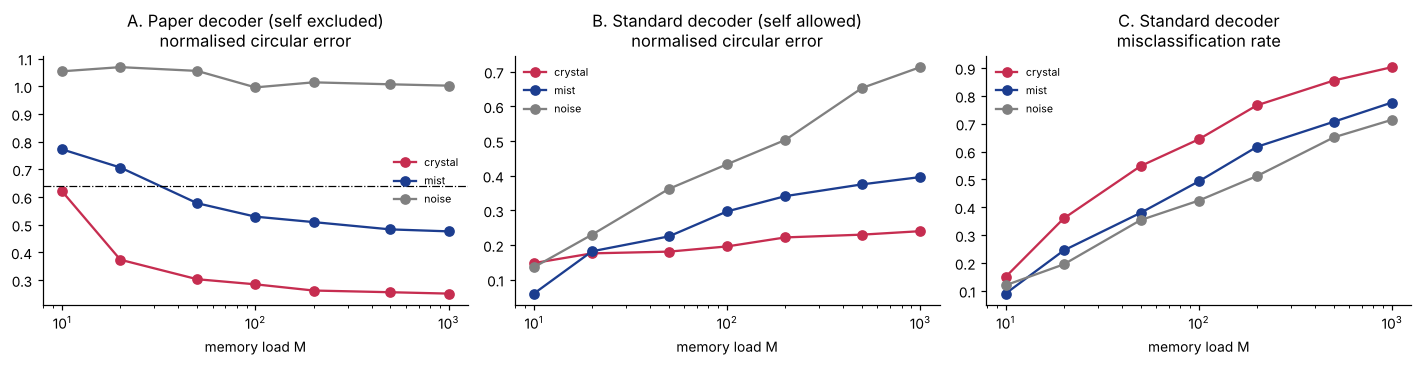

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
cols = {'crystal': C_T, 'mist': C_Z, 'noise': 'grey'}
for k in cols:
    axes[0].plot(LOADS, cap[k]['err'], 'o-', c=cols[k], label=k)
    d_ = dec.loc[k]
    axes[1].plot(d_.index, d_['err_incl'], 'o-', c=cols[k], label=k)
    axes[2].plot(d_.index, d_['miscls_incl'], 'o-', c=cols[k], label=k)
axes[0].axhline(thr, ls='-.', c='k', lw=0.8)
axes[0].set_title('A. Paper decoder (self excluded)\nnormalised circular error')
axes[1].set_title('B. Standard decoder (self allowed)\nnormalised circular error')
axes[2].set_title('C. Standard decoder\nmisclassification rate')
for a in axes: a.set_xscale('log'); a.set_xlabel('memory load M'); a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

**Reading the three panels.**

* **A** reproduces Fig. 3a: all errors fall with load, and the "capacity" ratio is an artefact of the grid edges.
* **B** is an ordinary noisy nearest-template decoder. Topography still helps on the *circular-distance* metric at large
  $M$ (errors become near-misses), which is the textbook graded-error property of population codes. But error now rises
  with load, as it should, and at small $M$ all codes are equivalent.
* **C** is the metric the Methods say was used. For exact identification the crystal code is the **worst** at every load:
  neighbouring templates are similar, so they are easier to confuse. This is the classic discrimination–generalisation
  trade-off, and it cuts against "topology maximises capacity".

So the model supports a modest, standard claim (topographic codes fail gracefully) and does not support ">100-fold capacity".

## 3.3 Is there a phase transition in $\tau$?

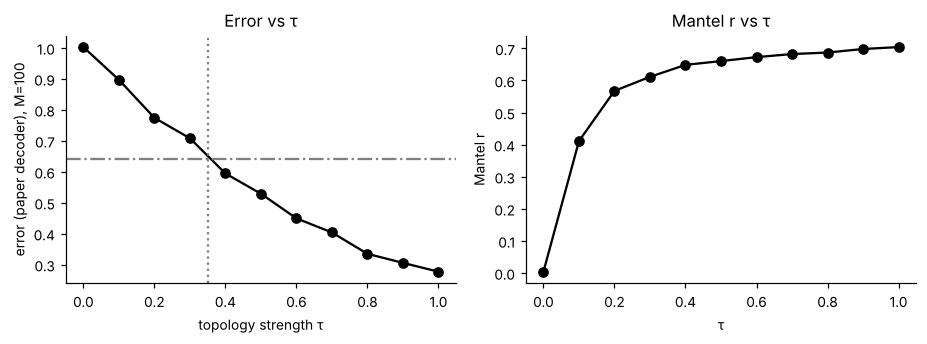

tau       0.000  0.100  0.200  0.300  0.400  0.500  0.600  0.700  0.800  0.900  1.000
error     1.003  0.897  0.774  0.708  0.594  0.529  0.449  0.404  0.335  0.306  0.277
mantel_r  0.004  0.411  0.568  0.611  0.649  0.660  0.673  0.682  0.687  0.698  0.704
Linear fit: slope=-0.733, max |residual| = 0.073  (R^2 = 0.969)


In [5]:
rng = np.random.RandomState(320)
lv, te, tm = t3mod.topology_sensitivity(0.2, 500, 0.15, 20, rng, n_mem=100)
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.2))
ax[0].plot(lv, te, 'ko-'); ax[0].axhline(thr, ls='-.', c='grey'); ax[0].axvline(0.35, ls=':', c='grey')
ax[0].set_xlabel('topology strength τ'); ax[0].set_ylabel('error (paper decoder), M=100'); ax[0].set_title('Error vs τ')
ax[1].plot(lv, tm, 'ko-'); ax[1].set_xlabel('τ'); ax[1].set_ylabel('Mantel r'); ax[1].set_title('Mantel r vs τ')
plt.tight_layout(); plt.show()
lin = np.polyfit(lv, te, 1); resid = te - np.polyval(lin, lv)
print(pd.DataFrame({'tau': lv, 'error': te.round(3), 'mantel_r': tm.round(3)}).T.to_string(header=False))
print(f"Linear fit: slope={lin[0]:.3f}, max |residual| = {np.abs(resid).max():.3f}  (R^2 = {1 - resid.var()/te.var():.3f})")

Error falls almost linearly with $\tau$ (the paper's own Results text calls it "smooth … rather than emerging at a
discrete threshold"). $\tau_{crit}\approx0.35$ is simply where a straight line crosses a threshold defined as the midpoint
of its own endpoints; in `fig_3.py` both `ERR_THRESH = 0.1601` and `TAU_CRIT = 0.35` are hard-coded. Nothing here
behaves like a phase transition (no discontinuity, no divergence, no finite-size scaling).

A second problem is the mapping to birds. Mantel $r$ saturates fast: $\tau=0.1$ already gives $r\approx0.4$ and mist
($\tau=0.5$) gives $r\approx0.66$, close to crystal's 0.70. The measured values (chickadee ≈0.42, finch ≈0.23, Part 1) are not
calibrated to any $\tau$; the labels "crystal = chickadee, mist = finch" are assigned, not estimated. The "empirical
sparsity $\rho\approx0.15$" is likewise a hard-coded constant (`fig_3.py`, `fig_parameter_sweep.py`), never computed
from data. Section 3.5 estimates it.

## 3.4 The 10,000-configuration sweep

The sweep is $N\in\{25..500\}\times\rho\in\{0.01..0.25\}\times T\in\{25..500\}$. **$T$ is the number of Monte-Carlo
repetitions** (`n_trials` in `test_all_decoders`), not a property of the network, so invariance to $T$ is guaranteed by
construction. That leaves 500 distinct network configurations. A reduced grid with both decoders is enough to see the
structure (the full sweep takes days).

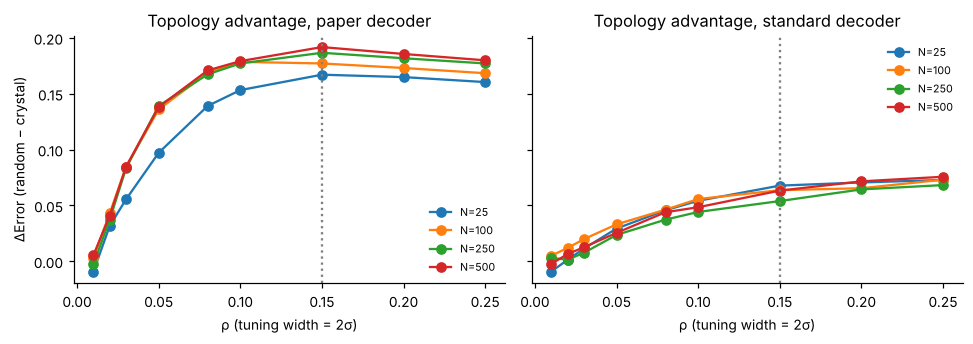

     adv_paper                      adv_standard                     
N          25     100    250    500          25     100    250    500
rho                                                                  
0.01    -0.009  0.003 -0.003  0.005       -0.009  0.005  0.003 -0.002
0.02     0.032  0.043  0.037  0.041        0.001  0.012  0.001  0.007
0.03     0.056  0.085  0.083  0.085        0.011  0.020  0.008  0.013
0.05     0.097  0.136  0.139  0.138        0.029  0.033  0.024  0.025
0.08     0.139  0.169  0.167  0.171        0.046  0.046  0.037  0.044
0.10     0.153  0.179  0.177  0.179        0.054  0.056  0.044  0.048
0.15     0.167  0.177  0.187  0.192        0.068  0.064  0.054  0.063
0.20     0.165  0.173  0.182  0.186        0.071  0.065  0.064  0.072
0.25     0.160  0.168  0.177  0.180        0.073  0.073  0.068  0.076


In [6]:
def adv(N, rho, reps=15, exclude_self=True):
    out = []
    for s in range(reps):
        r = np.random.RandomState(s)
        Mc, l = t3mod.generate_code(100, N, rho, r, 1.0)
        Mr, _ = t3mod.generate_code(100, N, rho, r, 0.0)
        out.append(nn_decode(Mr, l, r, exclude_self=exclude_self)[0] - nn_decode(Mc, l, r, exclude_self=exclude_self)[0])
    return np.mean(out) * 0.25   # back to raw circular units, as in the paper's sweep

sw = []
for N in [25, 100, 250, 500]:
    for rho in [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25]:
        sw.append(dict(N=N, rho=rho, adv_paper=adv(N, rho, exclude_self=True), adv_standard=adv(N, rho, exclude_self=False)))
sw = pd.DataFrame(sw)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for N, g in sw.groupby('N'):
    ax[0].plot(g.rho, g.adv_paper, 'o-', label=f'N={N}'); ax[1].plot(g.rho, g.adv_standard, 'o-', label=f'N={N}')
ax[0].set_title('Topology advantage, paper decoder'); ax[1].set_title('Topology advantage, standard decoder')
for a in ax: a.axvline(0.15, ls=':', c='grey'); a.set_xlabel('ρ (tuning width = 2σ)'); a.legend(frameon=False, fontsize=7)
ax[0].set_ylabel('ΔError (random − crystal)'); plt.tight_layout(); plt.show()
print(sw.pivot(index='rho', columns='N', values=['adv_paper', 'adv_standard']).round(3).to_string())

With the paper's decoder the advantage plateaus near 0.18 for $\rho\ge0.1$, matching Fig. 3b/S5. With a standard decoder
the advantage is about three times smaller and keeps rising with tuning width (wider fields give smoother codes), so the
"saturated optimum at the empirical ρ" disappears. Note also that $\rho$ here is tuning **width** ($\sigma=\rho/2$),
not the activity sparsity the word suggests.

## 3.5 Empirical redundancy and the "169-fold geometric tax"

$R=\sum_k I_k / I_{pop}$, with $I_k$ = Skaggs information of each E cell (bits/spike) and $I_{pop}=-\tfrac12\log_2(1-R^2)$
from a cross-validated ridge regression of bin row/column on the z-scored population vector (bits per sample, Gaussian
channel). Sessions with $I_{pop}<0.05$ bits are dropped in the "filtered" analysis.

In [ ]:
red = []
for sp_ in ['chickadee', 'finch']:
    g = E[E.sp == sp_]
    for k, sub in g.groupby('session'):                       # author's grouping (session only)
        maps = [np.nan_to_num(np.asarray(m, float).ravel()) for m in sub['map'] if np.size(m) == NB]
        if len(maps) < 5:
            continue
        M = np.vstack(maps); info = sub['info'].values[:len(maps)]
        _, ipop = t3mod.compute_population_info(M)
        red.append(dict(sp=sp_, session=k, n=len(maps), sum_info=info[info > 0].sum(), ipop=ipop,
                        R=t3mod.compute_redundancy(M, info)))
R = pd.DataFrame(red)
for lab, sub in [('unfiltered', R.dropna(subset=['R'])), ('filtered Ipop>=0.05', R[(R.ipop >= 0.05)].dropna(subset=['R']))]:
    a, b = sub[sub.sp == 'chickadee'].R, sub[sub.sp == 'finch'].R
    print(f"{lab:22s} chickadee mean {a.mean():7.1f} median {a.median():5.1f} (n={len(a)}) | finch mean {b.mean():5.1f} "
          f"median {b.median():4.1f} (n={len(b)}) | MW p={mannwhitneyu(a, b).pvalue:.3f}")
top = R.sort_values('R', ascending=False).head(3)[['sp', 'n', 'sum_info', 'ipop', 'R']]
print('\nLargest ratios:\n', top.round(4).to_string(index=False))
ck_u = R[(R.sp == 'chickadee')].R.dropna()
print(f"\nChickadee unfiltered mean without the single largest session: {ck_u.sort_values().iloc[:-1].mean():.1f}")
print(f"Spearman(R, n neurons) across sessions: {spearmanr(R.dropna(subset=['R']).R, R.dropna(subset=['R']).n)[0]:.2f}")

**What to check in the output above.** `fig_3.py` labels each of the four groups in Fig. 3c with its *mean*, and the
169× label sits over the unfiltered chickadee group — the group whose mean the paper's own text says is "inflated by a
small number of sessions with very low $I_{pop}$" (one session ≈3311× at $I_{pop}\approx0.001$ bits). If the unfiltered
chickadee mean printed above is ≈169 and drops sharply without the largest session, then the "169-fold geometric tax"
that the Discussion calls "the theoretical optimum … predicted by the idealised crystalline model" is an empirical
outlier-driven mean; no part of the model computes a redundancy. Independently of that: the ratio divides bits/spike by
bits/sample, so its magnitude has no absolute meaning, and its numerator grows with the number of cells while the
denominator saturates, so it scales with ensemble size (see the Spearman correlation with n).

---
# Part 4 — Claim-by-claim verdict

*Status: Tier 3 simulation results below are executed. Tier 1/2 and the empirical-redundancy rows are filled in after
the notebook has been run on the Payne et al. data (Parts 0–2, 3.5).*

| # | Paper claim | Reproduced? | Holds up? | Why |
|---|---|---|---|---|
| T3-1 | Crystal / mist / noise error 0.285 / 0.529 / 0.996 at M=100; threshold 0.640 | **Yes, exactly** | — | Same code, same seed |
| T3-2 | Crystal capacity > 1000 vs mist < 10 → ">100-fold capacity advantage" | Yes (numbers) | **No** | Values are the two ends of the tested grid; all error curves *fall* with load because the decoder excludes the correct template |
| T3-3 | Error metric = misclassification rate with self-match excluded | — | **No** | That quantity is identically 1.0; the code actually uses normalised circular distance |
| T3-4 | Topology maximises capacity | Partly | **Weak** | With a standard decoder, crystal codes are *worse* at exact identification at every load; they only give smaller circular errors (graded failure), a known property |
| T3-5 | "Phase transition" at τ_crit ≈ 0.35 | — | **No** | Error vs τ is close to linear (R² ≈ 0.97); τ_crit and threshold are hard-coded in `fig_3.py` |
| T3-6 | Advantage robust over 10,000 configurations, invariant to N and T, saturating at empirical ρ ≈ 0.15 | Pattern yes | **Overstated** | T is the Monte-Carlo repeat count (invariance by construction) → 500 real configs; ρ = 0.15 is a hard-coded constant; with a standard decoder the advantage is ~3× smaller and does not saturate |
| T3-7 | 169-fold "geometric tax" = model optimum | — | **No** | 169× is the unfiltered empirical chickadee mean in Fig. 3c (outlier-driven); the model computes no redundancy; ratio mixes bits/spike and bits/sample |
| T1 | Chickadee Shesha 0.245 vs finch 0.166; Mantel 0.42 vs 0.23; controls | *pending data* | *pending* | Key tests: excess over circular-shift null by species; species effect after controlling mean spatial info & N; bird-level aggregation |
| T2 | E/I: Bayesian Δ = 0.076; angles 14/64/82°; D 7.5 → 9.8; synergy | *pending data* | *pending* | Known code issues: `tier2_enhanced.py` stacks 40×40 maps unflattened; MCMC fixes I mean & SDs; "anti-correlated" control spans E's subspace by construction; D and synergy confounded with neuron count |